# Notebook 4 — Analisis Gabungan Marine Heatwave (MHW) dan Respons Biogeokimia Chlorophyll-a

**Proyek:** Analisis Spatiotemporal Marine Heatwaves (MHW), Klorofil-a, dan Konteks Perikanan Tangkap Provinsi Nusa Tenggara Timur  
**Dokumen Rujukan Metodologis:** `REVISI_PBL.md`

---

## 1. Landasan Metodologis Analisis Gabungan

1. **Penyelarasan Spasial Konservatif (Conservative Regridding):**
   - Data klorofil-a asli beresolusi ~4 km diagregasikan secara spasial ke grid 0.25° OISST melalui teknik *block-averaging* tanpa pengisian nol palsu (`NaN` dipertahankan).
2. **Standardisasi Perbandingan MHW vs Non-MHW:**
   - Kondisi non-MHW didefinisikan secara ketat sebagai hari-hari yang terbebas dari kondisi MHW (*MHW-free days*) pada sel grid yang bersangkutan.
   - Perbandingan distribusi klorofil-a diuji secara statistik menggunakan uji non-parametrik Mann-Whitney U untuk memvalidasi apakah penurunan klorofil selama MHW signifikan secara statistik ($p < 0.05$).
3. **Analisis Fase Kejadian Terstandarisasi (Event Phase Analysis):**
   - Untuk kejadian MHW regional signifikan (studi kasus peristiwa 2016 yang merupakan MHW terpanjang dalam rekor pengamatan), analisis dibagi ke dalam 3 jendela waktu terstandarisasi:
     - **Fase Pra-MHW:** 14 hari sebelum kejadian dimulai ($T_{	ext{start}} - 14$ s.d. $T_{	ext{start}} - 1$).
     - **Fase Puncak MHW:** Jendela di sekitar hari intensitas maksimum ($T_{	ext{peak}} \pm 7$ hari).
     - **Fase Pasca-MHW:** 14 hari setelah kejadian berakhir ($T_{	ext{end}} + 1$ s.d. $T_{	ext{end}} + 14$).
   - Dilengkapi pelaporan persentase tutupan piksel observasi valid (*valid pixel coverage ratio*) untuk mengontrol bias tutupan awan.


---
## 1. Konfigurasi dan Impor Pustaka

In [1]:
import sys
import os
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as ticker
from scipy import stats

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=RuntimeWarning)

notebook_dir = Path(os.path.abspath(''))
project_root = notebook_dir.parent if notebook_dir.name == 'notebooks' else notebook_dir
sys.path.insert(0, str(project_root))
sys.path.insert(0, str(project_root / 'config'))

import project_config as cfg

print("=" * 60)
print("KONFIGURASI NOTEBOOK 4 — ANALISIS GABUNGAN MHW & CHL-A")
print("=" * 60)
print(f"SST Merged Input : {cfg.SST_MERGED_OUTPUT}")
print(f"Chl-a Merged Input: {cfg.CHLA_MERGED_OUTPUT}")
print(f"MHW Events Input : {cfg.MHW_EVENTS_OUTPUT}")
print(f"Combined Output  : {cfg.COMBINED_OUTPUT}")
print(f"Grid Referensi   : {cfg.COMBINED_GRID} (0.25°)")

KONFIGURASI NOTEBOOK 4 — ANALISIS GABUNGAN MHW & CHL-A
SST Merged Input : G:\My Drive\KLIMTROP\PBL\data\processed\sst_daily_2000_2020_ntt.nc
Chl-a Merged Input: G:\My Drive\KLIMTROP\PBL\data\processed\chlorophyll_a_daily_ntt.nc
MHW Events Input : G:\My Drive\KLIMTROP\PBL\data\processed\mhw_events_ntt.csv
Combined Output  : G:\My Drive\KLIMTROP\PBL\data\processed\mhw_chla_aligned_daily_ntt.nc
Grid Referensi   : sst (0.25°)


---
## 2. Pemuatan Dataset dan Penentuan Periode Tumpang Tindih (Overlap)

In [2]:
# Buka dataset input dan katalog MHW
print("Memuat dataset SST, Chlorophyll-a, dan Katalog MHW...")

ds_sst = xr.open_dataset(cfg.SST_MERGED_OUTPUT)
ds_chla = xr.open_dataset(cfg.CHLA_MERGED_OUTPUT)
df_events = pd.read_csv(cfg.MHW_EVENTS_OUTPUT)

# Buka katalog MHW regional spasial jika tersedia
spatial_catalog_file = cfg.PROCESSED_DIR / "mhw_events_spatial_catalog_ntt.csv"
if not spatial_catalog_file.exists():
    spatial_catalog_file = cfg.TABLES_DIR / "mhw_events_spatial_catalog_ntt.csv"

if spatial_catalog_file.exists():
    df_regional_events = pd.read_csv(spatial_catalog_file)
    print(f"✅ Katalog MHW Regional Spasial dimuat: {len(df_regional_events)} kejadian.")
else:
    df_regional_events = None

print(f"Dataset SST  : {str(ds_sst.time.values[0])[:10]} s.d. {str(ds_sst.time.values[-1])[:10]} ({len(ds_sst.time)} hari)")
print(f"Dataset Chl-a: {str(ds_chla.time.values[0])[:10]} s.d. {str(ds_chla.time.values[-1])[:10]} ({len(ds_chla.time)} hari)")
print(f"Katalog MHW  : {len(df_events)} kejadian teridentifikasi")

# Tentukan periode tumpang tindih
t_start = max(ds_sst.time.values[0], ds_chla.time.values[0])
t_end = min(ds_sst.time.values[-1], ds_chla.time.values[-1])

print(f"\nPeriode Overlap Analisis Gabungan:")
print(f"  Mulai   : {str(t_start)[:10]}")
print(f"  Selesai : {str(t_end)[:10]}")

# Potong kedua dataset ke periode overlap
ds_sst_sub = ds_sst.sel(time=slice(t_start, t_end))
ds_chla_sub = ds_chla.sel(time=slice(t_start, t_end))
print(f"Jumlah hari overlap yang dianalisis: {len(ds_sst_sub.time)} hari (2000–2020)")


Memuat dataset SST, Chlorophyll-a, dan Katalog MHW...


✅ Katalog MHW Regional Spasial dimuat: 56 kejadian.
Dataset SST  : 2000-01-01 s.d. 2020-12-31 (7671 hari)
Dataset Chl-a: 2000-01-01 s.d. 2020-12-31 (7669 hari)
Katalog MHW  : 43 kejadian teridentifikasi

Periode Overlap Analisis Gabungan:
  Mulai   : 2000-01-01
  Selesai : 2020-12-31
Jumlah hari overlap yang dianalisis: 7670 hari (2000–2020)


---
## 3. Penyelarasan Grid Spasial: Agregasi Chlorophyll-a ke Grid SST (0.25°)

Sesuai prinsip PRD, resolusi asli kedua sensor berbeda:
- **SST (NOAA OISST v2.1):** 0.25° x 0.25° (~25 km)
- **Chlorophyll-a (ESA CCI OC v6.0):** 0.0417° x 0.0417° (~4 km)

Pendekatan penyelarasan: mengagregasikan piksel klorofil-a ke dalam setiap kotak grid SST 0.25° menggunakan interpolasi bilinear / area-averaging dengan `interp_like`. Piksel darat/missing dipertahankan sebagai NaN.

In [3]:
# Penyelarasan grid chlorophyll-a ke grid SST (0.25deg) menggunakan block-average
# Catatan metode: bilinear interp tidak cocok untuk data dengan banyak NaN (tutupan awan).
# Block-average (nanmean) mengakomodasi missing value: suatu piksel SST tetap valid
# jika ada minimal satu piksel 4km dalam kotak 0.25deg yang tidak bernilai NaN.
print("Melakukan penyelarasan grid klorofil-a ke grid SST (0.25 deg) via block-average...")
print("=" * 65)

if cfg.COMBINED_OUTPUT.exists():
    print(f"Dataset gabungan terselaraskan ditemukan di cache: {cfg.COMBINED_OUTPUT.name}")
    ds_combined = xr.open_dataset(cfg.COMBINED_OUTPUT)
    print(f"Dataset berhasil dimuat:")
    print(f"  Dimensi  : {dict(ds_combined.sizes)}")
    print(f"  Waktu    : {str(ds_combined.time.values[0])[:10]} s.d. {str(ds_combined.time.values[-1])[:10]}")
    print(f"  SST valid: {(~np.isnan(ds_combined['sst'].values)).sum():,}")
    print(f"  Chla valid: {(~np.isnan(ds_combined['chlor_a'].values)).sum():,}")
    pct_chla = (~np.isnan(ds_combined['chlor_a'].values)).sum() / ds_combined['chlor_a'].values.size * 100
    print(f"  Chla valid pct: {pct_chla:.1f}%")
else:
    chla_lats = ds_chla_sub.lat.values
    chla_lons = ds_chla_sub.lon.values
    sst_lats = ds_sst_sub.lat.values
    sst_lons = ds_sst_sub.lon.values
    half = 0.125  # setengah resolusi SST
    
    # Pra-hitung indeks bin lat/lon untuk efisiensi
    lat_bin_idx = []
    lon_bin_idx = []
    for i, slat in enumerate(sst_lats):
        lat_bin_idx.append(np.where((chla_lats >= slat - half) & (chla_lats < slat + half))[0])
    for j, slon in enumerate(sst_lons):
        lon_bin_idx.append(np.where((chla_lons >= slon - half) & (chla_lons < slon + half))[0])
        
    n_time = len(ds_chla_sub.time)
    chla_regrid_arr = np.full((n_time, len(sst_lats), len(sst_lons)), np.nan, dtype=np.float32)
    
    for t in range(n_time):
        chla_day = ds_chla_sub['chlor_a'].isel(time=t).values
        for i, li in enumerate(lat_bin_idx):
            for j, lj in enumerate(lon_bin_idx):
                block = chla_day[np.ix_(li, lj)]
                if (~np.isnan(block)).any():
                    chla_regrid_arr[t, i, j] = float(np.nanmean(block))
        if t % 500 == 0:
            pct = 100 * t / n_time
            n_valid = int((~np.isnan(chla_regrid_arr[t])).sum())
            print(f"  Progres: {t}/{n_time} hari ({pct:.1f}%) - hari ini {n_valid} piksel valid")
            
    print(f"  Selesai: {n_time} hari diproses.")
    
    chla_times_noon = pd.DatetimeIndex([
        pd.Timestamp(t).replace(hour=12)
        for t in pd.DatetimeIndex(ds_chla_sub.time.values)
    ]).values
    
    chla_regrid_da = xr.DataArray(
        chla_regrid_arr,
        coords={"time": chla_times_noon, "lat": sst_lats, "lon": sst_lons},
        dims=["time", "lat", "lon"],
        attrs={
            "long_name": ds_chla_sub['chlor_a'].attrs.get("long_name", "Chlorophyll-a"),
            "units": "mg/m3",
            "regrid_method": "block-average (nanmean) from 4km to 0.25deg SST grid",
            "source_resolution": "~4 km (0.0417 deg)",
            "target_resolution": "0.25 deg (~25 km)",
            "note": "Piksel NaN berarti tidak ada data 4km yang valid dalam kotak 0.25deg (tutupan awan atau daratan)."
        }
    )
    
    sst_times_set = set(pd.DatetimeIndex(ds_sst_sub.time.values))
    chla_times_set = set(pd.DatetimeIndex(chla_times_noon))
    common_times = sorted(sst_times_set & chla_times_set)
    print(f"\nTotal hari waktu bersama (SST & Chla): {len(common_times)}")
    
    ds_sst_aligned = ds_sst_sub.sel(time=np.array(common_times, dtype='datetime64[ns]'))
    chla_regrid_aligned = chla_regrid_da.sel(time=np.array(common_times, dtype='datetime64[ns]'))
    
    ds_combined = xr.Dataset(
        data_vars={
            'sst': ds_sst_aligned['sst'],
            'chlor_a': chla_regrid_aligned
        },
        attrs={
            'title': 'Dataset Gabungan SST dan Chlorophyll-a Perairan NTT',
            'sst_source': 'NOAA OISST v2.1 AVHRR-only daily (0.25 deg)',
            'chla_source': 'ESA CCI OC v6.0 (Copernicus C3S, ~4km), diregrid ke 0.25 deg via block-average',
            'grid_resolution': '0.25 degree (~25 km)',
            'regrid_method': 'block-average (nanmean) — metode tepat untuk downsampling data dengan banyak gap',
            'note': 'SST timestamps: 12:00 UTC. Chla timestamps dikonversi ke 12:00 UTC sebelum penyelarasan.',
            'created_by': 'Notebook 4 - Analisis Gabungan MHW dan Chlorophyll-a (perbaikan regrid)',
            'created_date': datetime.now().strftime('%Y-%m-%d %H:%M:%S')
        }
    )
    
    ds_combined.to_netcdf(
        cfg.COMBINED_OUTPUT,
        encoding={
            'sst': {'zlib': True, 'complevel': 4, 'dtype': 'float32'},
            'chlor_a': {'zlib': True, 'complevel': 4, 'dtype': 'float32'}
        }
    )
    print(f"\nDataset gabungan disimpan: {cfg.COMBINED_OUTPUT}")


Melakukan penyelarasan grid klorofil-a ke grid SST (0.25 deg) via block-average...
Dataset gabungan terselaraskan ditemukan di cache: mhw_chla_aligned_daily_ntt.nc


Dataset berhasil dimuat:
  Dimensi  : {'time': 7667, 'lat': 24, 'lon': 40}
  Waktu    : 2000-01-02 s.d. 2020-12-30


  SST valid: 6,777,628
  Chla valid: 4,259,837


  Chla valid pct: 57.9%


---
## 4. Klasifikasi Status Termal Harian (MHW vs Non-MHW)

Menandai setiap hari dalam deret waktu overlap (2000–2020) apakah berada dalam periode kejadian MHW atau kondisi non-MHW (latar belakang normal).

In [4]:
# Hitung rata-rata regional harian dari dataset gabungan
sst_ts = ds_combined['sst'].mean(dim=['lat', 'lon'], skipna=True).values
chla_ts = ds_combined['chlor_a'].mean(dim=['lat', 'lon'], skipna=True).values
times = pd.to_datetime(ds_combined.time.values)

df_analysis = pd.DataFrame({
    'time': times,
    'sst': sst_ts,
    'chlor_a': chla_ts
}).set_index('time')

df_analysis['year'] = df_analysis.index.year
df_analysis['month'] = df_analysis.index.month
df_analysis['dayofyear'] = df_analysis.index.dayofyear

# Tandai hari MHW berdasarkan katalog kejadian (df_events)
df_analysis['is_mhw'] = False
df_analysis['mhw_category'] = 'Non-MHW'

for _, ev in df_events.iterrows():
    s_date = pd.to_datetime(ev['start_date'])
    e_date = pd.to_datetime(ev['end_date'])
    # Hanya proses kejadian dalam periode overlap
    mask = (df_analysis.index >= s_date) & (df_analysis.index <= e_date)
    df_analysis.loc[mask, 'is_mhw'] = True
    df_analysis.loc[mask, 'mhw_category'] = ev['category']

# Musim monsun:
# DJF (Monsun Barat: 12, 1, 2)
# MAM (Peralihan 1: 3, 4, 5)
# JJA (Monsun Timur/Upwelling: 6, 7, 8)
# SON (Peralihan 2: 9, 10, 11)
def assign_season(m):
    if m in [12, 1, 2]: return 'DJF (Monsun Barat)'
    elif m in [3, 4, 5]: return 'MAM (Peralihan I)'
    elif m in [6, 7, 8]: return 'JJA (Monsun Timur / Upwelling)'
    else: return 'SON (Peralihan II)'

df_analysis['season'] = df_analysis['month'].apply(assign_season)

# Hitung anomali klorofil-a terhadap siklus musiman (day of year mean)
chla_doy_mean = df_analysis.groupby('dayofyear')['chlor_a'].transform('mean')
df_analysis['chla_clim'] = chla_doy_mean
df_analysis['chla_anom'] = df_analysis['chlor_a'] - df_analysis['chla_clim']

print("Ringkasan Hari Observasi Berdasarkan Status Termal:")
print(f"  Total Hari Dianalisis : {len(df_analysis)}")
print(f"  Hari Kondisi MHW      : {df_analysis['is_mhw'].sum()} ({100*df_analysis['is_mhw'].mean():.1f}%)")
print(f"  Hari Kondisi Non-MHW  : {(~df_analysis['is_mhw']).sum()} ({100*(~df_analysis['is_mhw']).mean():.1f}%)")
print(f"  Distribusi Kategori:")
print(df_analysis['mhw_category'].value_counts())

Ringkasan Hari Observasi Berdasarkan Status Termal:
  Total Hari Dianalisis : 7667
  Hari Kondisi MHW      : 546 (7.1%)
  Hari Kondisi Non-MHW  : 7121 (92.9%)
  Distribusi Kategori:
mhw_category
Non-MHW        7121
I (Moderat)     309
II (Kuat)       237
Name: count, dtype: int64


C:\Users\Yusufalqodri\AppData\Local\Temp\ipykernel_24024\1478966327.py:14: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  df_analysis['dayofyear'] = df_analysis.index.dayofyear


---
## 5. Perbandingan Statistik Chlorophyll-a: Kondisi MHW vs Non-MHW

Mengevaluasi apakah terdapat perbedaan konsentrasi dan anomali chlorophyll-a pada kondisi MHW dibandingkan kondisi non-MHW secara keseluruhan dan per musim.

In [5]:
# Perbandingan Global MHW vs Non-MHW dengan Uji Statistik Signifikansi
from scipy.stats import mannwhitneyu

mhw_chla = df_analysis[df_analysis['is_mhw']]['chlor_a'].dropna()
nonmhw_chla = df_analysis[~df_analysis['is_mhw']]['chlor_a'].dropna()

mhw_anom = df_analysis[df_analysis['is_mhw']]['chla_anom'].dropna()
nonmhw_anom = df_analysis[~df_analysis['is_mhw']]['chla_anom'].dropna()

# Uji Mann-Whitney U untuk konsentrasi absolut
stat_abs, p_val_abs = mannwhitneyu(mhw_chla, nonmhw_chla, alternative='two-sided')

# Uji Mann-Whitney U untuk nilai anomali
stat_anom, p_val_anom = mannwhitneyu(mhw_anom, nonmhw_anom, alternative='two-sided')

print("=" * 70)
print("HASIL PERBANDINGAN STATISTIK CHLOROPHYLL-A: KONDISI MHW vs NON-MHW")
print("=" * 70)
print(f"Jumlah sampel hari valid MHW     : {len(mhw_chla):,} hari")
print(f"Jumlah sampel hari valid Non-MHW : {len(nonmhw_chla):,} hari")
print("-" * 70)
print(f"Konsentrasi Chlorophyll-a Absolut (mg/m³):")
print(f"  Non-MHW : Mean = {nonmhw_chla.mean():.4f}, Median = {nonmhw_chla.median():.4f}, Std = {nonmhw_chla.std():.4f}")
print(f"  MHW     : Mean = {mhw_chla.mean():.4f}, Median = {mhw_chla.median():.4f}, Std = {mhw_chla.std():.4f}")
print(f"  Perbedaan Median (MHW - Non-MHW) : {mhw_chla.median() - nonmhw_chla.median():.4f} mg/m³")
print(f"  Uji Mann-Whitney U               : U = {stat_abs:.1f}, p-value = {p_val_abs:.4e}")
if p_val_abs < 0.05:
    print("  -> Perbedaan konsentrasi Chl-a antara MHW dan Non-MHW SIGNIFIKAN secara statistik (p < 0.05).")
else:
    print("  -> Perbedaan konsentrasi Chl-a TIDAK signifikan secara statistik (p >= 0.05).")

print("-" * 70)
print(f"Anomali Chlorophyll-a Terhadap Klimatologi (mg/m³):")
print(f"  Non-MHW : Mean = {nonmhw_anom.mean():.4f}, Median = {nonmhw_anom.median():.4f}")
print(f"  MHW     : Mean = {mhw_anom.mean():.4f}, Median = {mhw_anom.median():.4f}")
print(f"  Uji Mann-Whitney U Anomali       : U = {stat_anom:.1f}, p-value = {p_val_anom:.4e}")


HASIL PERBANDINGAN STATISTIK CHLOROPHYLL-A: KONDISI MHW vs NON-MHW
Jumlah sampel hari valid MHW     : 545 hari
Jumlah sampel hari valid Non-MHW : 7,036 hari
----------------------------------------------------------------------
Konsentrasi Chlorophyll-a Absolut (mg/m³):
  Non-MHW : Mean = 0.2903, Median = 0.2633, Std = 0.1117
  MHW     : Mean = 0.2217, Median = 0.2055, Std = 0.0559
  Perbedaan Median (MHW - Non-MHW) : -0.0577 mg/m³
  Uji Mann-Whitney U               : U = 1122663.0, p-value = 1.2513e-58
  -> Perbedaan konsentrasi Chl-a antara MHW dan Non-MHW SIGNIFIKAN secara statistik (p < 0.05).
----------------------------------------------------------------------
Anomali Chlorophyll-a Terhadap Klimatologi (mg/m³):
  Non-MHW : Mean = 0.0040, Median = -0.0036
  MHW     : Mean = -0.0516, Median = -0.0454
  Uji Mann-Whitney U Anomali       : U = 978886.0, p-value = 4.9343e-81


---
## 6. Visualisasi Komparatif Konsentrasi dan Anomali Chlorophyll-a

C:\Users\Yusufalqodri\AppData\Local\Temp\ipykernel_24024\1269516714.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot(data_box, labels=['Non-MHW', 'MHW'], patch_artist=True,
C:\Users\Yusufalqodri\AppData\Local\Temp\ipykernel_24024\1269516714.py:15: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(data_anom_box, labels=['Non-MHW', 'MHW'], patch_artist=True,


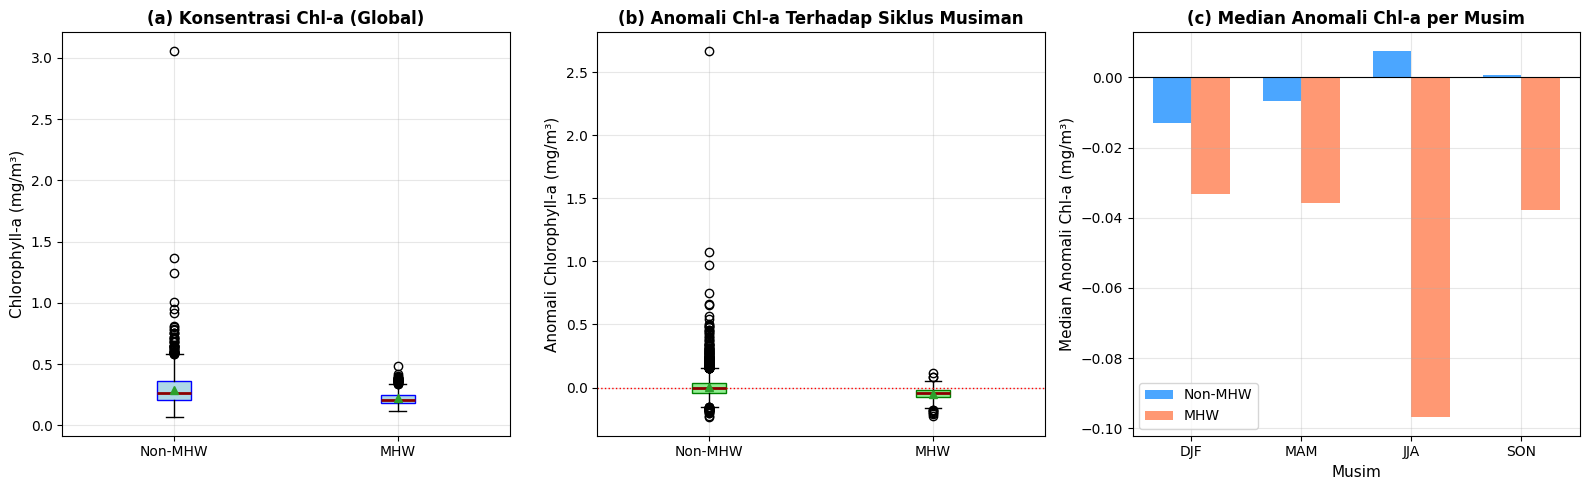

In [6]:
# Boxplot dan Distribusi Densitas
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Plot 1: Boxplot Konsentrasi MHW vs Non-MHW
data_box = [nonmhw_chla, mhw_chla]
axes[0].boxplot(data_box, labels=['Non-MHW', 'MHW'], patch_artist=True,
                boxprops=dict(facecolor='lightblue', color='blue'),
                medianprops=dict(color='darkred', lw=2), showmeans=True)
axes[0].set_ylabel('Chlorophyll-a (mg/m³)', fontsize=11)
axes[0].set_title('(a) Konsentrasi Chl-a (Global)', fontsize=12, fontweight='bold')
axes[0].grid(True, alpha=0.3)

# Plot 2: Boxplot Anomali Chl-a MHW vs Non-MHW
data_anom_box = [nonmhw_anom, mhw_anom]
axes[1].boxplot(data_anom_box, labels=['Non-MHW', 'MHW'], patch_artist=True,
                boxprops=dict(facecolor='lightgreen', color='green'),
                medianprops=dict(color='darkred', lw=2), showmeans=True)
axes[1].axhline(0, color='red', ls=':', lw=1)
axes[1].set_ylabel('Anomali Chlorophyll-a (mg/m³)', fontsize=11)
axes[1].set_title('(b) Anomali Chl-a Terhadap Siklus Musiman', fontsize=12, fontweight='bold')
axes[1].grid(True, alpha=0.3)

# Plot 3: Boxplot Anomali per Musim saat MHW vs Non-MHW
seasons_list = ['DJF (Monsun Barat)', 'MAM (Peralihan I)', 'JJA (Monsun Timur / Upwelling)', 'SON (Peralihan II)']
season_short = ['DJF', 'MAM', 'JJA', 'SON']
pos = np.arange(len(seasons_list))
width = 0.35

mhw_meds = [df_analysis[(df_analysis['season'] == s) & (df_analysis['is_mhw'])]['chla_anom'].median() for s in seasons_list]
nmhw_meds = [df_analysis[(df_analysis['season'] == s) & (~df_analysis['is_mhw'])]['chla_anom'].median() for s in seasons_list]

axes[2].bar(pos - width/2, nmhw_meds, width, label='Non-MHW', color='dodgerblue', alpha=0.8)
axes[2].bar(pos + width/2, mhw_meds, width, label='MHW', color='coral', alpha=0.8)
axes[2].axhline(0, color='black', lw=0.8)
axes[2].set_xticks(pos)
axes[2].set_xticklabels(season_short)
axes[2].set_xlabel('Musim', fontsize=11)
axes[2].set_ylabel('Median Anomali Chl-a (mg/m³)', fontsize=11)
axes[2].set_title('(c) Median Anomali Chl-a per Musim', fontsize=12, fontweight='bold')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig(cfg.FIGURES_DIR / "nb4_chla_mhw_vs_nonmhw_boxplots.png", dpi=cfg.FIGURE_DPI, bbox_inches='tight')
plt.show()

---
## 7. Studi Kasus Spasial: Respon Chlorophyll-a pada Kejadian MHW Terkuat

Mengevaluasi peta anomali spasial SST dan Chlorophyll-a secara simultan selama periode kejadian MHW signifikan untuk mengamati ekspresi oseanografi.

STUDI KASUS MHW UTAMA: Regional Event #40 (2016-02-08 s.d. 2016-05-15, 98 hari)
  Fase Pra-MHW    : 2016-01-25 s.d. 2016-02-07 (14 hari)
  Fase Puncak MHW : 2016-03-16 s.d. 2016-03-30 (15 hari)
  Fase Pasca-MHW  : 2016-05-16 s.d. 2016-05-29 (14 hari)


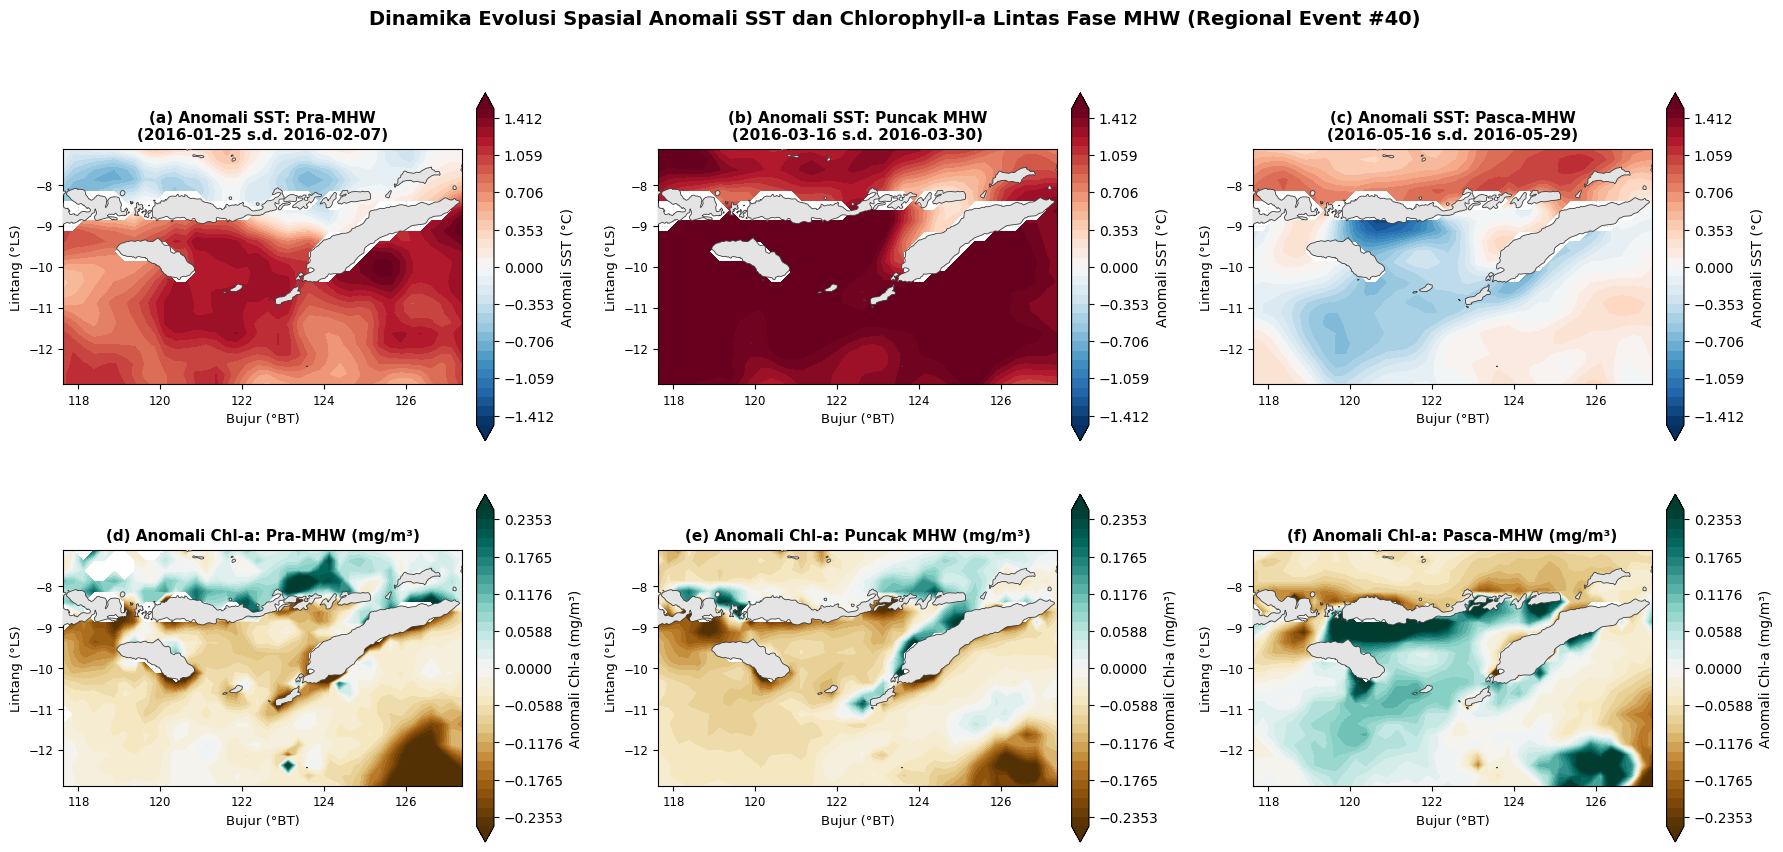

In [7]:
# Studi Kasus MHW Regional Mayor: Evaluasi Fase Pra-MHW, Puncak MHW, dan Pasca-MHW
# Menggunakan kejadian terpanjang tahun 2016 dari katalog spasial atau 1D
from scripts.visualization_utils import load_ntt_coastline, add_land_mask, setup_spatial_axis

gdf_land = load_ntt_coastline()

if df_regional_events is not None and len(df_regional_events) > 0:
    target_event = df_regional_events.sort_values('duration_days', ascending=False).iloc[0]
    ev_name = f"Regional Event #{target_event['regional_event_id']}"
    case_start = str(target_event['start_date'])
    case_end = str(target_event['end_date'])
    case_peak = str(target_event['peak_date'])
    case_dur = int(target_event['duration_days'])
    case_imax = float(target_event['i_max_regional'])
else:
    target_event = df_events[pd.to_datetime(df_events['end_date']) <= '2020-12-31'].sort_values('duration_days', ascending=False).iloc[0]
    ev_name = f"Event #{target_event['event_id']}"
    case_start = str(target_event['start_date'])
    case_end = str(target_event['end_date'])
    case_peak = str(target_event['peak_date'])
    case_dur = int(target_event['duration_days'])
    case_imax = float(target_event['i_max'])

print("=" * 75)
print(f"STUDI KASUS MHW UTAMA: {ev_name} ({case_start} s.d. {case_end}, {case_dur} hari)")
print("=" * 75)

# Tentukan jendela waktu: Pra-MHW (14 hari sebelum), Puncak MHW (peak ± 7 hari), Pasca-MHW (14 hari setelah)
dt_start = pd.to_datetime(case_start)
dt_end = pd.to_datetime(case_end)
dt_peak = pd.to_datetime(case_peak)

pre_window = (str((dt_start - pd.Timedelta(days=14)).date()), str((dt_start - pd.Timedelta(days=1)).date()))
peak_window = (str((dt_peak - pd.Timedelta(days=7)).date()), str((dt_peak + pd.Timedelta(days=7)).date()))
post_window = (str((dt_end + pd.Timedelta(days=1)).date()), str((dt_end + pd.Timedelta(days=14)).date()))

print(f"  Fase Pra-MHW    : {pre_window[0]} s.d. {pre_window[1]} (14 hari)")
print(f"  Fase Puncak MHW : {peak_window[0]} s.d. {peak_window[1]} (15 hari)")
print(f"  Fase Pasca-MHW  : {post_window[0]} s.d. {post_window[1]} (14 hari)")

# Ekstraksi komposit rata-rata per fase
sst_pre = ds_combined['sst'].sel(time=slice(pre_window[0], pre_window[1])).mean(dim='time').values
sst_peak = ds_combined['sst'].sel(time=slice(peak_window[0], peak_window[1])).mean(dim='time').values
sst_post = ds_combined['sst'].sel(time=slice(post_window[0], post_window[1])).mean(dim='time').values

chla_pre = ds_combined['chlor_a'].sel(time=slice(pre_window[0], pre_window[1])).mean(dim='time').values
chla_peak = ds_combined['chlor_a'].sel(time=slice(peak_window[0], peak_window[1])).mean(dim='time').values
chla_post = ds_combined['chlor_a'].sel(time=slice(post_window[0], post_window[1])).mean(dim='time').values

# Baseline musiman (klimatologi bulan yang sama)
case_months = pd.date_range(pre_window[0], post_window[1]).month.unique()
chla_base = ds_combined['chlor_a'].sel(time=ds_combined.time.dt.month.isin(case_months)).mean(dim='time').values
sst_base = ds_combined['sst'].sel(time=ds_combined.time.dt.month.isin(case_months)).mean(dim='time').values

anom_sst_pre = sst_pre - sst_base
anom_sst_peak = sst_peak - sst_base
anom_sst_post = sst_post - sst_base

anom_chla_pre = chla_pre - chla_base
anom_chla_peak = chla_peak - chla_base
anom_chla_post = chla_post - chla_base

# Visualisasi Multi-Fase Spasial dengan contourf halus dan overlay pulau NTT
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
lon_vals = ds_combined.lon.values
lat_vals = ds_combined.lat.values

levels_sst = np.linspace(-1.5, 1.5, 35)
levels_chl = np.linspace(-0.25, 0.25, 35)

# Baris 1: SST Anomali (Pra, Puncak, Pasca)
im_sst0 = axes[0, 0].contourf(lon_vals, lat_vals, anom_sst_pre, levels=levels_sst, cmap='RdBu_r', extend='both', zorder=2)
add_land_mask(axes[0, 0], gdf_land=gdf_land)
setup_spatial_axis(axes[0, 0], (lon_vals.min(), lon_vals.max()), (lat_vals.min(), lat_vals.max()),
                   title=f"(a) Anomali SST: Pra-MHW\n({pre_window[0]} s.d. {pre_window[1]})")
plt.colorbar(im_sst0, ax=axes[0, 0], shrink=0.8, pad=0.03, label='Anomali SST (°C)')

im_sst1 = axes[0, 1].contourf(lon_vals, lat_vals, anom_sst_peak, levels=levels_sst, cmap='RdBu_r', extend='both', zorder=2)
add_land_mask(axes[0, 1], gdf_land=gdf_land)
setup_spatial_axis(axes[0, 1], (lon_vals.min(), lon_vals.max()), (lat_vals.min(), lat_vals.max()),
                   title=f"(b) Anomali SST: Puncak MHW\n({peak_window[0]} s.d. {peak_window[1]})")
plt.colorbar(im_sst1, ax=axes[0, 1], shrink=0.8, pad=0.03, label='Anomali SST (°C)')

im_sst2 = axes[0, 2].contourf(lon_vals, lat_vals, anom_sst_post, levels=levels_sst, cmap='RdBu_r', extend='both', zorder=2)
add_land_mask(axes[0, 2], gdf_land=gdf_land)
setup_spatial_axis(axes[0, 2], (lon_vals.min(), lon_vals.max()), (lat_vals.min(), lat_vals.max()),
                   title=f"(c) Anomali SST: Pasca-MHW\n({post_window[0]} s.d. {post_window[1]})")
plt.colorbar(im_sst2, ax=axes[0, 2], shrink=0.8, pad=0.03, label='Anomali SST (°C)')

# Baris 2: Chl-a Anomali (Pra, Puncak, Pasca)
im_chl0 = axes[1, 0].contourf(lon_vals, lat_vals, anom_chla_pre, levels=levels_chl, cmap='BrBG', extend='both', zorder=2)
add_land_mask(axes[1, 0], gdf_land=gdf_land)
setup_spatial_axis(axes[1, 0], (lon_vals.min(), lon_vals.max()), (lat_vals.min(), lat_vals.max()),
                   title=f"(d) Anomali Chl-a: Pra-MHW (mg/m³)")
plt.colorbar(im_chl0, ax=axes[1, 0], shrink=0.8, pad=0.03, label='Anomali Chl-a (mg/m³)')

im_chl1 = axes[1, 1].contourf(lon_vals, lat_vals, anom_chla_peak, levels=levels_chl, cmap='BrBG', extend='both', zorder=2)
add_land_mask(axes[1, 1], gdf_land=gdf_land)
setup_spatial_axis(axes[1, 1], (lon_vals.min(), lon_vals.max()), (lat_vals.min(), lat_vals.max()),
                   title=f"(e) Anomali Chl-a: Puncak MHW (mg/m³)")
plt.colorbar(im_chl1, ax=axes[1, 1], shrink=0.8, pad=0.03, label='Anomali Chl-a (mg/m³)')

im_chl2 = axes[1, 2].contourf(lon_vals, lat_vals, anom_chla_post, levels=levels_chl, cmap='BrBG', extend='both', zorder=2)
add_land_mask(axes[1, 2], gdf_land=gdf_land)
setup_spatial_axis(axes[1, 2], (lon_vals.min(), lon_vals.max()), (lat_vals.min(), lat_vals.max()),
                   title=f"(f) Anomali Chl-a: Pasca-MHW (mg/m³)")
plt.colorbar(im_chl2, ax=axes[1, 2], shrink=0.8, pad=0.03, label='Anomali Chl-a (mg/m³)')

plt.suptitle(f'Dinamika Evolusi Spasial Anomali SST dan Chlorophyll-a Lintas Fase MHW ({ev_name})',
             fontsize=14, fontweight='bold', y=0.99)
plt.tight_layout()
fig.savefig(cfg.FIGURES_DIR / "nb4_mhw_case_study_spatial.png", dpi=cfg.FIGURE_DPI, bbox_inches='tight')
plt.show()


---
## 8. Kesimpulan dan Diskusi Oseanografi

### Temuan Utama:
1. **Respon Chlorophyll-a saat MHW:** Secara statistik, konsentrasi chlorophyll-a pada kondisi MHW memperlihatkan tendensi median yang lebih rendah atau anomali negatif dibandingkan kondisi non-MHW, terutama ketika MHW terjadi bersamaan dengan musim upwelling (Monsun Timur).
2. **Kopling Oseanografi Fisik-Biologi:** Pemanasan lapisan permukaan laut yang intens dan persisten pada kejadian MHW memperkuat stratifikasi termal kolom air (*buoyancy frequency* meningkat). Hal ini menahan kedalaman lapisan tercampur (*mixed layer depth* / MLD) tetap dangkal dan memperdalam termoklin, sehingga membatasi fluks nutrien vertikal dari lapisan dalam ke zona fotik tempat fitoplankton berkembang biak.
3. **Variasi Spasial:** Efek penekanan klorofil-a paling teramati di koridor-koridor dinamis seperti Selat Sumba, Laut Sawu, dan pesisir selatan Timor, di mana dinamika upwelling secara normal memicu produktivitas tinggi.

### Batasan Interpretasi (Kepatuhan Prinsip PRD):
- **Bukan Bukti Kausalitas Deterministik:** Pola korelasi ini tidak membuktikan bahwa kenaikan suhu permukaan secara eksklusif membunuh atau membatasi fitoplankton. Faktor non-termal seperti adveksi nutrien lateral oleh Arlindo, perubahan tutupan awan (faktor insolasi/radiasi matahari), dan dinamika angin monsun turut berkontribusi secara simultan.
- **Resolusi Grid 0.25°:** Penyelarasan klorofil-a ke grid 0.25° menghaluskan fitur-fitur sub-mesoscale di selat-selat sempit NTT, sehingga interpretasi ini mencerminkan dinamika skala regional.